# Confirmación independiente de las bases del residuo

Se comparan POD sin centrar, PCA centrada y PCA + media con igual dimensión total por semilla e intervalo, QR directo y reconstrucción del lote hasta 128 con el mismo prefijo Sobol. La media ocupa una dirección dentro del presupuesto. Se conserva la pérdida solo PDE, transformación IC/BC, red 3×32, Adam, candidatos fijos y veinte snapshots cada cinco pasos del último intervalo de cien.

El calendario de dimensiones se extrae de la trayectoria PCA + media al 95 % generada en las semillas nuevas con la regla congelada al 95 %, antes de ejecutar POD y PCA centrada. POD y PCA centrada usan ese calendario, no eligen su propio rango ni umbral. Es un control condicional emparejado para comparar subespacios a igual presupuesto; no evalúa sus versiones adaptativas autónomas. PCA + media y Sobol se ejecutan nuevamente para esta cohorte; sus archivos se reutilizan únicamente dentro de este estudio. La dimensión total incluye la media independiente en la referencia.

POD toma los primeros d modos de R; PCA toma los primeros d componentes de R centrada por punto. Se construyen bases ortonormales antes del mismo QR. El selector falla explícitamente si no alcanza el rango numérico solicitado, sin añadir direcciones artificiales. Las historias iniciales son comunes; después evolucionan con cada red. Las coordenadas y el complemento Sobol permanecen emparejados.

Diez semillas nuevas 2091–2100, cien pasos uniformes y diez mil de continuación. El protocolo se congela antes de ejecutar las cuarenta corridas. Comparación principal: PCA centrada menos POD en RMSE terminal. Los demás contrastes son secundarios y descriptivos. No hay datos supervisados en el objetivo, poda ni ampliación log-det.

| Base/control | RMSE prueba ± DE | Residuo RMS |
|---|---:|---:|
| POD sin centrar | 0.12834 ± 0.06442 | 0.27063 |
| PCA centrada | 0.12256 ± 0.06346 | 0.31890 |
| PCA + media | 0.14940 ± 0.05770 | 0.30514 |
| Sobol | 0.24395 ± 0.10885 | 0.91721 |


PCA + media frente a POD sin centrar: diferencia media RMSE +0.02106; mejora en 2/10 semillas; bootstrap pareado 95 % [-0.01827, +0.05368].

PCA centrada frente a POD sin centrar: diferencia media RMSE -0.00578; mejora en 5/10 semillas; bootstrap pareado 95 % [-0.06129, +0.04410].

PCA + media frente a PCA centrada: diferencia media RMSE +0.02684; mejora en 4/10 semillas; bootstrap pareado 95 % [-0.01368, +0.06957].

POD sin centrar frente a Sobol: diferencia media RMSE -0.11560; mejora en 9/10 semillas; bootstrap pareado 95 % [-0.18413, -0.04667].

PCA centrada frente a Sobol: diferencia media RMSE -0.12139; mejora en 9/10 semillas; bootstrap pareado 95 % [-0.19742, -0.04849].

PCA + media frente a Sobol: diferencia media RMSE -0.09455; mejora en 8/10 semillas; bootstrap pareado 95 % [-0.16574, -0.02121].

**Comparación**

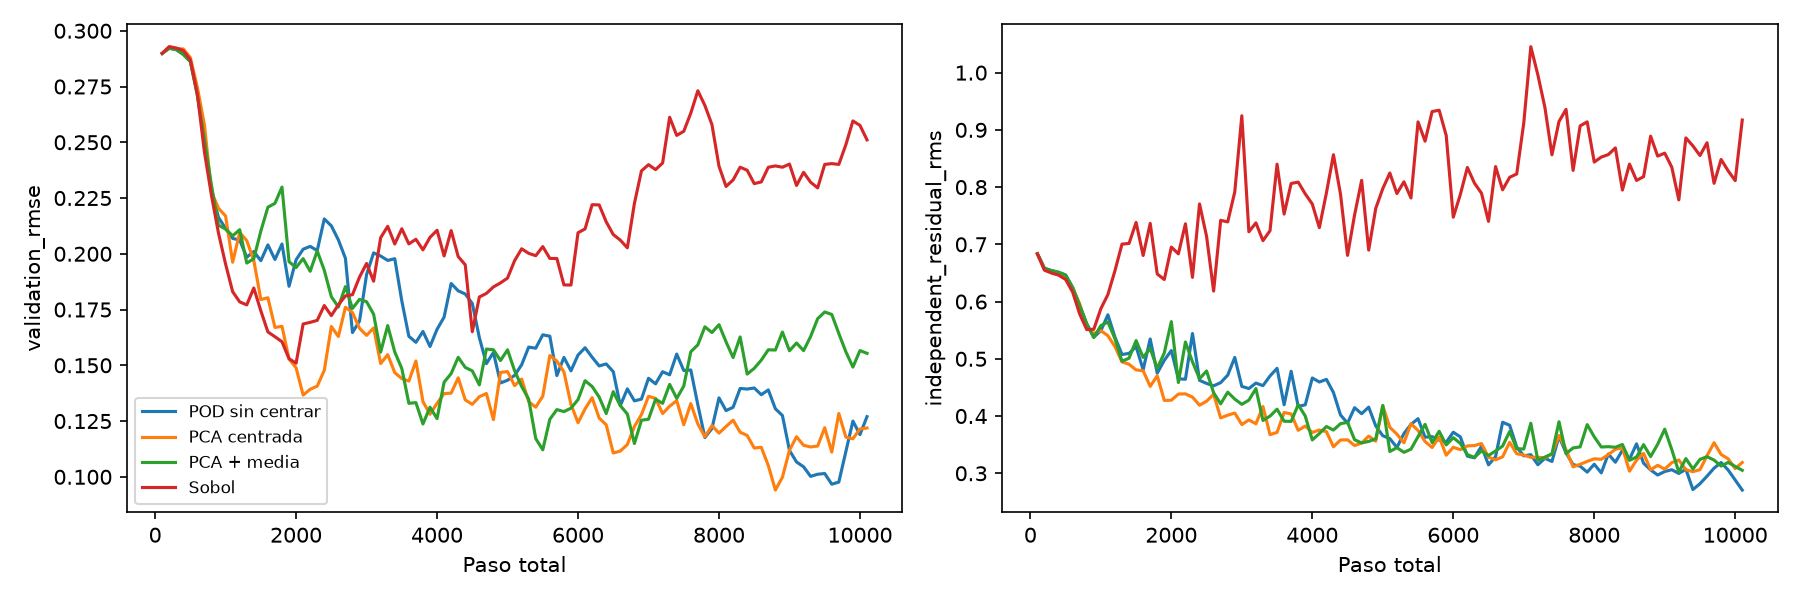

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/pde_bases/matched_pde_bases_confirmation_10fresh_10k_v1/comparison.png'), format='png', embed=True))


Se evalúa el modelo terminal en prueba reservada sin ajustar parámetros a prueba. DE describe dispersión entre semillas. El bootstrap con diez diferencias es exploratorio y no corrige multiplicidad. El menor residuo no garantiza menor error de solución. Las fracciones de energía, fluctuaciones y media se guardan para POD/PCA centrada; los brazos que generan la referencia de rangos no incluyen esas columnas y se dejan vacías.

Las auditorías reconstruyen cien selecciones QR y comprueban calendario de rangos, tamaño activo, complemento Sobol e inicio común. Las restricciones IC/BC se verifican por el mismo mecanismo del notebook 26. manifest.json identifica cada procedencia.

Reproducir: `python scripts/run_collocation_pde_bases_confirmation.py`. Configuración en pca_collocation/configs/burgers_pde_bases_confirmation.json. Corridas completas se reutilizan. Las figuras están incrustadas como PNG.

## Resultado de la comparación principal

PCA centrada menos POD en RMSE terminal: diferencia media -0.00578; mejora en 5/10 semillas. Intervalo bootstrap pareado 95 % [-0.06129, +0.04410].

Criterio fijado: media negativa e intervalo completamente por debajo de cero. La ventaja no se confirma según este criterio; esto no demuestra equivalencia entre bases. Los contrastes secundarios se presentan como descriptivos. Diez semillas limitan la precisión de la estimación.